# Anchorage Harbor: a first ConvLSTM

Can a small neural network forecast the depth map ~4 weeks ahead better than the simple baselines?

1. Load the time-series dataset (`anchorage_timeseries.ipynb`)
2. Prepare the inputs and the target
3. The model: a ConvLSTM
4. Build it
5. Train it
6. Compare with the baselines on validation and test

A **ConvLSTM** is an LSTM where every multiplication is replaced by a small convolution:
it reads the 4 input maps one after another, like an LSTM reads a sequence, but its memory is itself a map,
so each square remembers what happened around it.

## 1. Load

From `timeseries.npz` we need:
- `maps` (697, 173, 91): depth maps in ft, NaN = not measured
- `windows` (515, 5): for each sample, the positions of its 4 input maps and its target map
- `masks` (515, 173, 91): which squares of each sample count (channel, measured, not dredged)
- `split` (515,): train / val / test
- `dates`, `dredged`: only for the shoaling-rate baseline in step 6

In [1]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/ehydro/anchorage'
except ImportError:              # not in Colab: the data folder next to the notebook
    DATA_DIR = 'data'

d = np.load(f'{DATA_DIR}/timeseries_v1/timeseries.npz')
maps, windows, masks, split = d['maps'], d['windows'], d['masks'], d['split']
dates, dredged = d['dates'], d['dredged']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('maps', maps.shape, ' windows', windows.shape, ' device', device)
for name in ['train', 'val', 'test']:
    print(f'  {name}: {(split == name).sum()} samples')

Mounted at /content/drive
maps (697, 173, 91)  windows (515, 5)  device cuda
  train: 367 samples
  val: 77 samples
  test: 71 samples


## 2. Prepare the inputs and the target

**Inputs.** Each of the 4 input maps becomes 2 channels:
- the depth, normalised with the mean and standard deviation of the training inputs, and 0 where not measured
- a "measured" channel: 1 where there is a depth, 0 where not, so the model can tell a real 0 from a gap

That gives `x` with shape (samples, 4 time steps, 2 channels, 173, 91).
We don't feed the dates: the inputs are always ~1 week apart and the target ~4 weeks after the last one.

**Target.** The model predicts the **change** from the last input to the target, not the depth itself.
The depth hardly moves in 4 weeks, so predicting the change puts all the effort on the part that matters,
and predicting 0 change is exactly the "nothing changes" baseline. The change is divided by its training
standard deviation so it is around ±1. Squares outside the mask get 0; the loss ignores them anyway.

The maps are used at full size, 173 x 91. No padding is needed: the model never shrinks the map.

In [2]:
inputs = maps[windows[:, :-1]]              # (samples, 4, H, W)
target = maps[windows[:, -1]]               # (samples, H, W)
last = inputs[:, -1]                        # the last input map
train = split == 'train'

MEAN, STD = np.nanmean(inputs[train]), np.nanstd(inputs[train])
measured = ~np.isnan(inputs)
x = np.stack([np.where(measured, (inputs - MEAN) / STD, 0), measured], axis=2).astype(np.float32)

change = np.where(masks, target - last, 0)                   # ft, 0 outside the mask
CHANGE_STD = change[train][masks[train]].std()
y = (change / CHANGE_STD).astype(np.float32)

x, y, m = torch.from_numpy(x), torch.from_numpy(y), torch.from_numpy(masks.astype(np.float32))
print('x', tuple(x.shape), ' y', tuple(y.shape), f' depth mean {MEAN:.1f} ft, std {STD:.1f} ft, change std {CHANGE_STD:.2f} ft')
print('any NaN left:', bool(torch.isnan(x).any() or torch.isnan(y).any()))

x (515, 4, 2, 173, 91)  y (515, 173, 91)  depth mean 46.7 ft, std 10.7 ft, change std 1.15 ft
any NaN left: False


## 3. The model

**`ConvLSTMCell`** is one step of the LSTM. It takes the current input map `x` and its own memory from the
previous step: `h` (what it outputs) and `c` (its long-term memory), both maps with `hidden` channels.
One convolution looks at `x` and `h` together and produces 4 maps, the usual LSTM gates:
- `i` input gate: how much new information to write into the memory
- `f` forget gate: how much of the old memory to keep
- `o` output gate: how much of the memory to show as `h`
- `g` the new information itself

**`ConvLSTM`** runs the cell over the 4 input maps in order, starting from an empty memory,
then a 1x1 convolution (the "head") turns the final `h` into one map: the predicted change.

In [3]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_channels, hidden):
        super().__init__()
        self.hidden = hidden
        self.conv = nn.Conv2d(in_channels + hidden, 4 * hidden, kernel_size=3, padding=1)

    def forward(self, x, h, c):
        i, f, o, g = self.conv(torch.cat([x, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTM(nn.Module):
    def __init__(self, in_channels=2, hidden=32):
        super().__init__()
        self.cell = ConvLSTMCell(in_channels, hidden)
        self.head = nn.Conv2d(hidden, 1, kernel_size=1)

    def forward(self, x):                                  # x: (batch, time, channels, H, W)
        batch, steps, _, H, W = x.shape
        h = torch.zeros(batch, self.cell.hidden, H, W, device=x.device)
        c = torch.zeros_like(h)
        for t in range(steps):
            h, c = self.cell(x[:, t], h, c)
        return self.head(h)[:, 0]                          # (batch, H, W): predicted change

## 4. Build it

In [4]:
torch.manual_seed(2)
np.random.seed(2)

model = ConvLSTM(in_channels=2, hidden=32).to(device)
print(model)
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')

ConvLSTM(
  (cell): ConvLSTMCell(
    (conv): Conv2d(34, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (head): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
)
39,329 parameters


## 5. Train

The **loss** is the mean squared error over the masked squares only: `(prediction − truth)²` is multiplied by the
mask (0 or 1) and divided by the number of masked squares. Squares outside the channel, unmeasured or dredged
contribute nothing.

Each epoch goes once through the training samples in random order, 8 at a time. After every epoch we measure
the **validation MAE in ft** (mean absolute error, in real units) and keep the weights of the best epoch.

In [5]:
EPOCHS = 30
BATCH = 8
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def masked_mse(pred, truth, mask):
    return ((pred - truth) ** 2 * mask).sum() / mask.sum()

def predict(indices):
    """Predicted change in ft for the given samples."""
    model.eval()
    out = []
    with torch.no_grad():
        for start in range(0, len(indices), BATCH):
            batch = indices[start:start + BATCH]
            out.append(model(x[batch].to(device)).cpu())
    return torch.cat(out).numpy() * CHANGE_STD

def mae(pred_change, indices):
    """Mean absolute error in ft over all masked squares of these samples."""
    truth, mask = change[indices], masks[indices]
    return np.abs(pred_change - truth)[mask].mean()

train_idx = np.where(split == 'train')[0]
val_idx = np.where(split == 'val')[0]
test_idx = np.where(split == 'test')[0]

best_mae, best_weights = np.inf, None
for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()
    order = np.random.permutation(train_idx)
    losses = []
    for start in range(0, len(order), BATCH):
        batch = order[start:start + BATCH]
        pred = model(x[batch].to(device))
        loss = masked_mse(pred, y[batch].to(device), m[batch].to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

    val_mae = mae(predict(val_idx), val_idx)
    if val_mae < best_mae:
        best_mae, best_weights = val_mae, copy.deepcopy(model.state_dict())
    print(f'epoch {epoch + 1:2d}  train loss {np.mean(losses):.3f}  val MAE {val_mae:.3f} ft'
          f'{"  *" if val_mae == best_mae else ""}  ({time.time() - start_time:.0f} s)')

model.load_state_dict(best_weights)
print(f'best val MAE {best_mae:.3f} ft')

epoch  1  train loss 0.936  val MAE 0.819 ft  *  (6 s)
epoch  2  train loss 0.907  val MAE 0.827 ft  (4 s)
epoch  3  train loss 0.886  val MAE 0.880 ft  (4 s)
epoch  4  train loss 0.844  val MAE 0.904 ft  (4 s)
epoch  5  train loss 0.831  val MAE 0.867 ft  (4 s)
epoch  6  train loss 0.826  val MAE 0.886 ft  (4 s)
epoch  7  train loss 0.823  val MAE 0.800 ft  *  (4 s)
epoch  8  train loss 0.821  val MAE 0.929 ft  (4 s)
epoch  9  train loss 0.808  val MAE 0.938 ft  (4 s)
epoch 10  train loss 0.787  val MAE 0.845 ft  (4 s)
epoch 11  train loss 0.762  val MAE 0.951 ft  (4 s)
epoch 12  train loss 0.755  val MAE 0.815 ft  (4 s)
epoch 13  train loss 0.747  val MAE 0.961 ft  (4 s)
epoch 14  train loss 0.749  val MAE 0.945 ft  (4 s)
epoch 15  train loss 0.724  val MAE 0.901 ft  (4 s)
epoch 16  train loss 0.714  val MAE 0.844 ft  (4 s)
epoch 17  train loss 0.721  val MAE 0.906 ft  (4 s)
epoch 18  train loss 0.704  val MAE 0.858 ft  (4 s)
epoch 19  train loss 0.709  val MAE 0.784 ft  *  (4 s)
epo

## 6. Compare with the baselines

Mean absolute error in ft over all masked squares, for:
- **nothing changes**: predict the last input map (change = 0)
- **shoaling rate**: every square keeps shoaling at its own average rate from the training years (2014–2022).
  The rate is the average change per day between consecutive surveys of the same season, leaving out dredged squares,
  times the days from the last input to the target
- **ConvLSTM**: the model above (best epoch on validation)

The test years are used only here, once.

In [8]:
days = dates.astype('int64')                 # date as a day number
year = dates.astype('datetime64[Y]').astype(int) + 1970

total_change = np.zeros(maps.shape[1:])
total_days = np.zeros(maps.shape[1:])
for p in range(len(maps) - 1):
    same_season = days[p + 1] - days[p] < 60
    if same_season and year[p + 1] <= 2022:
        step = maps[p + 1] - maps[p]
        ok = ~np.isnan(step) & ~dredged[p + 1]
        total_change[ok] += step[ok]
        total_days[ok] += days[p + 1] - days[p]
rate = np.where(total_days > 0, total_change / np.maximum(total_days, 1), 0)    # ft per day

def rate_prediction(indices):
    ahead = days[windows[indices, -1]] - days[windows[indices, -2]]             # days from last input to target
    return rate[None] * ahead[:, None, None]

print(f'{"":10} {"nothing changes":>16} {"shoaling rate":>14} {"ConvLSTM":>10}')
for name, idx in [('val', val_idx), ('test', test_idx)]:
    base = mae(np.zeros_like(change[idx]), idx)
    shoal = mae(rate_prediction(idx), idx)
    convlstm = mae(predict(idx), idx)
    print(f'{name:10} {base:13.3f} ft {shoal:11.3f} ft {convlstm:7.3f} ft')
    print(f'{"":10} {"":>16} {100 * (1 - shoal / base):12.0f} % {100 * (1 - convlstm / base):8.0f} %   better than nothing changes')

            nothing changes  shoaling rate   ConvLSTM
val                0.773 ft       0.815 ft   0.726 ft
                                      -6 %        6 %   better than nothing changes
test               0.698 ft       0.627 ft   0.574 ft
                                      10 %       18 %   better than nothing changes


One test sample: the true change over ~4 weeks and the two predictions (masked squares only, + = deeper).

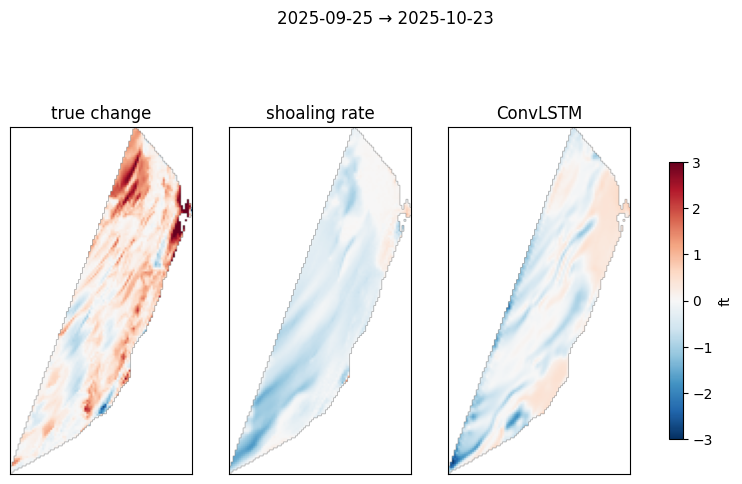

In [9]:
n = test_idx[len(test_idx) // 2]
w = windows[n]
panels = [(change[n], 'true change'),
          (rate_prediction(np.array([n]))[0], 'shoaling rate'),
          (predict(np.array([n]))[0], 'ConvLSTM')]

fig, axes = plt.subplots(1, 3, figsize=(10, 6))
for ax, (img, title) in zip(axes, panels):
    shown = ax.imshow(np.where(masks[n], img, np.nan), origin='lower', cmap='RdBu_r', vmin=-3, vmax=3)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(shown, ax=axes, shrink=0.6, label='ft')
fig.suptitle(f'{dates[w[-2]]} → {dates[w[-1]]}')
plt.show()

Ouput a test prediction

In [10]:
import json
from pyproj import Transformer

# the latest sample: 4 maps → prediction 4 weeks after the last one
n = len(windows) - 1
w = windows[n]
change = predict(np.array([n]))[0]                 # predicted change, ft
depth = maps[w[-2]] + change                       # predicted depth, ft below low tide

# each 10 m square → its 4 corners in latitude/longitude
to_latlon = Transformer.from_crs('EPSG:26934', 'EPSG:4326', always_xy=True)   # Alaska State Plane → lat/lon
row0, col0 = int(d['row0']), int(d['col0'])
show = d['core'] & ~np.isnan(depth)                # channel squares that have a prediction

features = []
for i, j in zip(*np.where(show)):
    x, y = (col0 + j) * 10, (row0 + i) * 10        # south-west corner of the square, metres
    corners = [(x, y), (x + 10, y), (x + 10, y + 10), (x, y + 10), (x, y)]
    features.append({
        'type': 'Feature',
        'geometry': {'type': 'Polygon', 'coordinates': [[list(to_latlon.transform(cx, cy)) for cx, cy in corners]]},
        'properties': {'depth_ft': round(float(depth[i, j]), 2), 'change_ft': round(float(change[i, j]), 2)},
    })

geojson = {'type': 'FeatureCollection',
           'properties': {'from_survey': str(dates[w[-2]]), 'predicted_for': str(dates[w[-1]])},
           'features': features}
json.dump(geojson, open('anchorage_prediction.geojson', 'w'))
print(len(features), 'squares, prediction for', dates[w[-1]])

from google.colab import files
files.download('anchorage_prediction.geojson')     # downloads the file to your computer

5500 squares, prediction for 2026-10-15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>